# R05 · Window-size sensitivity (Reviewer A)

**Reviewer A:** why W = 30 for SKAB and W = 50 for NAB?

The original values were set by hand: SKAB is sampled once per second and a fault lasts several minutes, so
30 s windows see a local stretch of the fault; NAB series are mostly 5-minute samples, so 50 steps ≈ 4 hours.
This notebook checks that the **conclusions** do not depend on that choice: B3 (+M3) and M1 are rerun with
other window sizes, 3 seeds each.
Window size is **not** selected on test data: the table is a robustness check, not a tuning step.

In [1]:
# ── Settings ──────────────────────────────────────────────────────────────
import os
WORKERS = int(os.environ.get("REV_WORKERS", 8))   # training jobs side by side on the GPU
DEVICE  = None     # None = use the GPU if there is one
RESULTS = os.environ.get("REV_RESULTS", "results")
RUN     = True     # False = skip training, only rebuild tables/figures from results/

import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import report, plots
from scripts.run_jobs import run_stage, stage_tags
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
os.makedirs("tables_rev", exist_ok=True)

def export(df, name):
    """Save a table as tables_rev/REV_<name>.csv and show it."""
    path = f"tables_rev/REV_{name}.csv"; df.to_csv(path); display(df); print("saved", path)

In [2]:
if RUN:
    failed = run_stage("window", workers=WORKERS, device=DEVICE, results=RESULTS)

grid winners: {'SKAB/dense': {'p': 0.05, 'lr': 0.001, 'latent': 64}, 'SKAB/lstm': {'p': 0.05, 'lr': 0.002, 'latent': 64}, 'NAB/dense': {'p': 0.05, 'lr': 0.002, 'latent': 64}, 'NAB/lstm': {'p': 0.05, 'lr': 0.001, 'latent': 16}}
stage=window  jobs=36  todo=36  workers=8  device=cuda  results=results


[1/36    0.4 min] kindae_datasetNAB_W20_archdense_p0.0_lr0.001_latent32_epochs50_patience5_seed1      21s


[2/36    0.6 min] kindae_datasetNAB_W20_archdense_p0.05_lr0.002_latent64_epochs100_patience10_seed1      33s


[3/36    0.6 min] kindae_datasetNAB_W20_archdense_p0.0_lr0.001_latent32_epochs50_patience5_seed2      37s


[4/36    0.7 min] kindae_datasetNAB_W20_archdense_p0.0_lr0.001_latent32_epochs50_patience5_seed0      37s


[5/36    0.7 min] kindae_datasetNAB_W20_archdense_p0.05_lr0.002_latent64_epochs100_patience10_seed2      38s


... (28 outputs left out)

[34/36    1.7 min] kindae_datasetSKAB_W100_archdense_p0.05_lr0.001_latent64_epochs100_patience10_seed2       5s


[35/36    1.7 min] kindae_datasetNAB_W100_archdense_p0.0_lr0.001_latent32_epochs50_patience5_seed2      32s


[36/36    1.7 min] kindae_datasetNAB_W100_archdense_p0.05_lr0.002_latent64_epochs100_patience10_seed2      33s


done in 1.8 min, 0 failed


In [3]:
df = report.load(RESULTS)
V = report.views(df)
print(len(df), "records")

250 records


auc_pr             f1 std/error_auroc margin/error_auroc       fpr@0.05  n_seeds
dataset method       W                                                                                           
NAB     B3 Dense AE  20   0.192 ± 0.002  0.237 ± 0.013             nan      0.620 ± 0.006            nan        3
                     30   0.209 ± 0.001  0.268 ± 0.001             nan      0.631 ± 0.003            nan        3
                     50   0.229 ± 0.000  0.294 ± 0.001             nan      0.648 ± 0.002            nan        3
                     100  0.274 ± 0.002  0.339 ± 0.002             nan      0.654 ± 0.001            nan        3
        M1 Dense+MCD 20   0.198 ± 0.001  0.261 ± 0.001   0.673 ± 0.045      0.626 ± 0.003            nan        3
                     30   0.209 ± 0.000  0.279 ± 0.001   0.712 ± 0.010      0.631 ± 0.002            nan        3
                     50   0.229 ± 0.001  0.295 ± 0.001   0.703 ± 0.014      0.646 ± 0.002            nan        3
                     100  0.271 ± 0.002  0.337 ± 0.001   0.690 ± 0.007      0.644 ± 0.006            nan        3
        M3 Dense+CP  20   0.192 ± 0.002  0.233 ± 0.009             nan                nan  0.077 ± 0.014        3
                     30   0.209 ± 0.001  0.254 ± 0.001             nan                nan  0.061 ± 0.001        3
                     50   0.229 ± 0.000  0.285 ± 0.001             nan                nan  0.059 ± 0.000        3
                     100  0.274 ± 0.002  0.335 ± 0.002             nan                nan  0.065 ± 0.001        3
SKAB    B3 Dense AE  20   0.842 ± 0.002  0.802 ± 0.000             nan      0.637 ± 0.003            nan        3
                     30   0.855 ± 0.000  0.817 ± 0.002             nan      0.647 ± 0.004            nan        3
                     50   0.880 ± 0.001  0.845 ± 0.003             nan      0.655 ± 0.014            nan        3
                     100  0.931 ± 0.001  0.884 ± 0.003             nan      0.784 ± 0.011            nan        3
        M1 Dense+MCD 20   0.840 ± 0.001  0.801 ± 0.001   0.413 ± 0.006      0.633 ± 0.002            nan        3
                     30   0.854 ± 0.001  0.815 ± 0.001   0.402 ± 0.002      0.647 ± 0.001            nan        3
                     50   0.876 ± 0.002  0.839 ± 0.001   0.364 ± 0.006      0.664 ± 0.008            nan        3
                     100  0.929 ± 0.000  0.887 ± 0.003   0.232 ± 0.012      0.769 ± 0.014            nan        3
        M3 Dense+CP  20   0.842 ± 0.002  0.765 ± 0.005             nan                nan  0.291 ± 0.011        3
                     30   0.855 ± 0.000  0.785 ± 0.004             nan                nan  0.309 ± 0.006        3
                     50   0.880 ± 0.001  0.845 ± 0.001             nan                nan  0.482 ± 0.004        3
                     100  0.931 ± 0.001  0.888 ± 0.006             nan                nan  0.891 ± 0.050        3

saved tables_rev/REV_tableG_window_size.csv


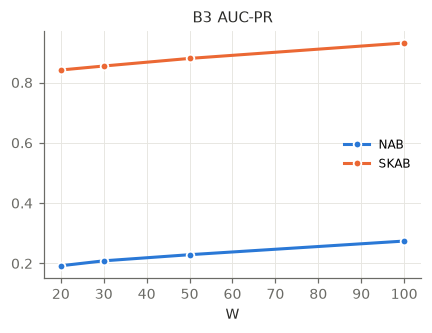

saved figures_rev/REV_window_size_B3.png


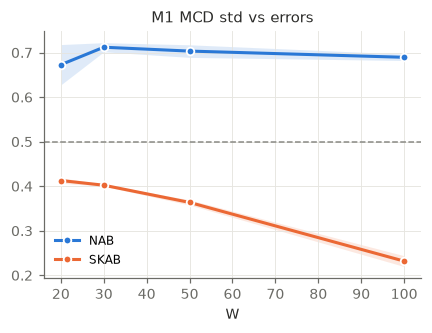

saved figures_rev/REV_window_size_M1.png


In [4]:
tags = stage_tags("window") | stage_tags("main")   # main runs give the default-W point
W = V[V.tag.isin(tags) & V.method.isin(["B3 Dense AE","M3 Dense+CP","M1 Dense+MCD"])
      & V.seed.isin(range(3))]
cols = ["auc_pr","f1","std/error_auroc","margin/error_auroc","fpr@0.05"]
cols = [c for c in cols if c in W]
export(report.mean_std(W, cols, by=("dataset","method","W")), "tableG_window_size")
fig, path = plots.sweep_lines(W[W.method == "B3 Dense AE"], "W", ["auc_pr"], ["B3 AUC-PR"], "REV_window_size_B3")
plt.show(); print("saved", path)
fig, path = plots.sweep_lines(W[W.method == "M1 Dense+MCD"], "W", ["std/error_auroc"],
                              ["M1 MCD std vs errors"], "REV_window_size_M1", ref=0.5)
plt.show(); print("saved", path)